# 03 · Feature engineering for the cardiac digital twin

This notebook adds the cardiac features from the feature plan (H1 to H7 and layers 1 to 5) on top of `02_merge_and_clean.ipynb`.

**Rule: real data only.** Each feature is computed from MIMIC-IV (vitals, rhythm, labs, ECG waveforms, medication orders and administrations, daily weights) or from the monitor recordings in `wearable_clean`. When the data needed for a feature does not exist (steps, accelerometer, walks, missed-dose taps, genetics, Lp(a)), the column is **not invented**: it is listed at the end as an app input or a watch signal for the live demo.

| Output (in `structured_csv/features/`) | One row = | What's in it |
|---|---|---|
| `ecg_features.csv` | one 12-lead ECG | QRS, QT, QTc, ST level and T wave in every lead, Q waves, ST elevation / depression flags, HRV |
| `hourly_cardiac_features.csv` | one ICU hour | AF burden, rhythm measures, HF warning signs, night SpO2 dips, QT risk (Tisdale), medication safety flags |
| `med_dose_checks.csv` | one drug administration | running daily total vs the daily limit (resets at midnight) |
| `wearable_features.csv` | one monitor record-hour | baseline deviation, HR spikes, SpO2 dips per hour, PVC burden, monitor QTc and ST |
| `cad_risk_table.csv` | one admission | ASCVD Pooled Cohort risk, CHA2DS2-VASc, HAS-BLED (partial), eGFR, troponin, CAD label |
| `model_features.csv` + `features_config.json` | one ICU hour | `model_ready` + the new hourly features, ready for training |
| `alert_rules.json`, `alert_log.csv` | alert tier rules and every alert they would fire | red / amber tiers with snooze and an alert-rate budget |
| `twin_rules.py` | – | rule functions for the app: alert tiers, symptom checklist, safe exercise zone, dose limit check |

The original CSVs and the `cleaned/` files are only read, never changed.

This notebook has **already been run**: every output is saved under its cell, with a **What this cell does** note above each code cell and a **Result** note below it. To rerun it, open it from the `Happiest_Health` folder and run all cells (about 1 minute).

## 0 · Setup

**What this cell does:** loads the cleaned tables from notebook 02 (`static_clean`, `dynamic_clean`, `clinical_clean`, `model_ready`, `wearable_clean`), the original `ecg.csv` and `diagnoses.csv`, and opens the two MIMIC zips (raw ECG waveforms; prescriptions, eMAR administrations and charted daily weights). New outputs go to `structured_csv/features/`.

In [1]:
import json, re, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=DeprecationWarning)

ROOT = Path("..") if Path("../data").exists() else Path(".")  # repo root (notebooks run from notebooks/)
DATA, CLEAN = ROOT / "data", ROOT / "data" / "cleaned"
FEAT = DATA / "features"
FIG = FEAT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

def save(df, name):
    df.to_csv(FEAT / f"{name}.csv", index=False)
    df.to_pickle(FEAT / f"{name}.pkl")
    print(f"saved features/{name:<26} {len(df):>7,} rows x {df.shape[1]} cols")

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=110)
    plt.show()

ld = lambda n: pd.read_pickle(CLEAN / f"{n}.pkl")
static_clean, dynamic_clean, clinical_clean = ld("static_clean"), ld("dynamic_clean"), ld("clinical_clean")
model_ready, wearable = ld("model_ready"), ld("wearable_clean")
config = json.loads((CLEAN / "preprocess_config.json").read_text())
ecg_basic = pd.read_csv(DATA / "ecg.csv", parse_dates=["ecg_time"])
diagnoses = pd.read_csv(DATA / "diagnoses.csv")
labs = clinical_clean[clinical_clean.source == "lab"]

# the two MIMIC zips: raw ECG waveforms, medication orders / administrations, daily weights
zclin = zipfile.ZipFile(next((ROOT / "data" / "raw").glob("mimic-iv-clinical-database-demo*.zip")))
zecg = zipfile.ZipFile(next((ROOT / "data" / "raw").glob("mimic-iv-ecg-demo*.zip")))
def ztable(z, rel, **kw):
    pre = z.namelist()[0].split("/")[0] + "/"
    return pd.read_csv(z.open(pre + rel), compression="gzip" if rel.endswith(".gz") else None, **kw)

report = {}
print("model_ready:", model_ready.shape, "| ICU hours:", len(dynamic_clean), "| ECGs:", len(ecg_basic))

model_ready: (4503, 154) | ICU hours: 12015 | ECGs: 659


**Result:** model_ready 4,503 × 154, 12,015 ICU hours, 659 ECGs loaded. Nothing is written yet.

# 1 · 12-lead ECG features (layer 4, H3 QTc)

**What this cell does (12-lead ECG, layer 4 and H3):** for each raw 10-second ECG:
1. Finds the R peaks (same detector as before) and builds a **median beat** for all 12 leads.
2. Finds QRS onset and the **J point** from the slope of all leads; the PR segment is the 0 mV baseline.
3. Measures the **ST level at J+60 ms** (J+40 ms if HR > 100), the **T-wave amplitude**, and **Q waves** (≥ 0.1 mV deep, ≥ 30 ms, ≥ 25% of R).
4. Measures **QT** (tangent method on the biggest T wave) and **QTc** (Bazett and Fridericia).
5. Flags: **ST elevation** (≥ 0.1 mV, ≥ 0.2 mV in V2-V3, in 2 neighbouring leads), **ST depression** (≤ -0.05 mV in 2 neighbouring leads), **T inversion** (2+ leads where T should be upright), **pathologic Q**, **QTc ≥ 500**, **irregular RR** (AF-like), and **LVH** (left ventricular hypertrophy, Sokolow-Lyon: S in V1 + R in V5/V6 ≥ 3.5 mV). ST is not read when QRS ≥ 120 ms (bundle branch block or pacing).

In [2]:
# ECG morphology from the raw 10-second, 500 Hz waveforms
LEADS_UPRIGHT_T = ["I", "II", "V3", "V4", "V5", "V6"]          # leads where T is normally upright
Q_LEADS = ["I", "II", "aVL", "aVF", "V2", "V3", "V4", "V5", "V6"]
CONTIGUOUS = {"inferior": ["II", "III", "aVF"], "lateral": ["I", "aVL", "V5", "V6"],
              "septal": ["V1", "V2"], "anterior": ["V3", "V4"]}

def read_ecg(rel):
    pre = zecg.namelist()[0].split("/")[0] + "/"
    hea = zecg.open(pre + rel + ".hea").read().decode().splitlines()
    head = hea[0].split()
    nsig, fs, nsamp = int(head[1]), float(head[2]), int(head[3])
    gains, base, names = [], [], []
    for line in hea[1:1 + nsig]:
        f = line.split()
        m = re.match(r"([\d.]+)(?:\((-?\d+)\))?", f[2])
        gains.append(float(m.group(1))); base.append(int(m.group(2) or 0)); names.append(f[-1])
    raw = np.frombuffer(zecg.open(pre + rel + ".dat").read(), dtype="<i2")[: nsamp * nsig].reshape(-1, nsig)
    sig = (raw.astype(float) - base) / gains
    sig[raw == -32768] = np.nan
    return sig, names, fs

def ma(s, k):
    k = max(int(k), 1)
    return np.convolve(s, np.ones(k) / k, "same")

def r_peaks(x, fs):
    # same detector as build_structured_csv.py (band-pass, slope energy, 300 ms refractory)
    x = np.nan_to_num(x - np.nanmedian(x))
    bp = ma(x, fs / 30) - ma(x, fs / 5)
    e = ma(np.abs(np.gradient(bp)), 0.08 * fs)
    thr, ref, w = 0.35 * np.percentile(e, 98), int(0.3 * fs), int(0.06 * fs)
    cand = np.flatnonzero((e[1:-1] > e[:-2]) & (e[1:-1] >= e[2:]) & (e[1:-1] > thr)) + 1
    pk = []
    for c in cand:
        if pk and c - pk[-1] < ref:
            if e[c] > e[pk[-1]]:
                pk[-1] = c
            continue
        pk.append(c)
    return np.array([max(c - w, 0) + int(np.argmax(np.abs(bp[max(c - w, 0):c + w]))) for c in pk], dtype=int)

def ecg_morphology(sig, names, fs, keep_beat=False):
    ms = lambda t: int(round(t * fs / 1000))
    x = np.nan_to_num(sig - np.nanmedian(sig, axis=0))
    x = np.column_stack([ma(x[:, j], ms(20)) for j in range(x.shape[1])])   # light smoothing, keeps the ST level
    found = {l: r_peaks(sig[:, names.index(l)], fs) for l in ("II", "V2", "V5") if l in names}
    counts = sorted(len(v) for v in found.values())
    pk = next(v for v in found.values() if len(v) == counts[len(counts) // 2])
    rr = np.diff(pk) / fs * 1000
    if len(rr) < 3:
        return None
    pre, post = ms(300), ms(min(650, np.median(rr) * 0.9))
    pk = pk[(pk > pre) & (pk < len(x) - post)]
    if len(pk) < 4:
        return None
    med = np.median(np.stack([x[p - pre:p + post] for p in pk]), axis=0)  # median beat, every lead
    R = pre
    slope = np.abs(np.gradient(med, axis=0)).sum(axis=1)
    thr = 0.15 * slope[R - ms(60):R + ms(60)].max()
    on, off = R - ms(20), R + ms(20)
    while on > R - ms(140) and slope[on] > thr: on -= 1                   # QRS onset
    while off < R + ms(160) and slope[off] > thr: off += 1                # J point (QRS end)
    med = med - med[on - ms(30):on - ms(5)].mean(axis=0)                  # PR segment = 0 mV baseline
    hr = 60000 / rr.mean()
    st = med[off + ms(60 if hr < 100 else 40)]                            # ST level at J+60 ms (J+40 if fast)
    t0, t1 = off + ms(120), min(len(med) - 1, R + ms(600))                  # T wave window (after the ST segment)
    tseg = med[t0:t1]
    t_amp = tseg[np.argmax(np.abs(tseg), axis=0), np.arange(med.shape[1])]
    # QT by the tangent method on the lead with the biggest T wave among II, V5, V2
    best = max([l for l in ("II", "V5", "V2") if l in names], key=lambda l: abs(t_amp[names.index(l)]))
    tl = med[:, names.index(best)] * np.sign(t_amp[names.index(best)])
    tp = t0 + int(np.argmax(tl[t0:t1]))
    d = np.gradient(tl)
    k = tp + int(np.argmin(d[tp:min(tp + ms(200), len(tl) - 1)]))
    t_end = k + (tl[k] / -d[k] if d[k] < 0 else 0)
    qt = (t_end - on) * 1000 / fs
    if not 250 <= qt / np.sqrt(rr.mean() / 1000) <= 700:                     # implausible: T end not found reliably
        qt = np.nan
    out = {"qrs_ms": (off - on) * 1000 / fs, "qt_ms": qt,
           "qtc_bazett_ms": qt / np.sqrt(rr.mean() / 1000), "qtc_fridericia_ms": qt / np.cbrt(rr.mean() / 1000)}
    for j, n in enumerate(names):
        q = med[on:R + 1, j]
        q_depth, q_dur, r_h = max(-q.min(), 0), (q < -0.02).sum() * 1000 / fs, med[on:off, j].max()
        out[f"st_{n}_mv"], out[f"t_{n}_mv"] = st[j], t_amp[j]
        out[f"q_{n}"] = int(n in Q_LEADS and q_depth >= 0.1 and q_dur >= 30 and q_depth >= 0.25 * max(r_h, 0.05))
    qrs = lambda n: med[on:off, names.index(n)] if n in names else np.array([0.0])
    out["sokolow_lyon_mv"] = -qrs("V1").min() + max(qrs("V5").max(), qrs("V6").max())   # S in V1 + tallest R in V5/V6
    if keep_beat:
        out["_beat"], out["_marks"], out["_names"], out["_fs"] = med, (on, off, t_end), names, fs
    return out

def ecg_flags(o, names):
    st = lambda n: o.get(f"st_{n}_mv", np.nan)
    ste = lambda n: st(n) >= (0.2 if n in ("V2", "V3") else 0.1)          # STEMI thresholds (simplified)
    std = lambda n: st(n) <= -0.05
    f = {"wide_qrs": int(o["qrs_ms"] >= 120)}                              # bundle branch block / paced: ST not interpretable
    pairs = list(CONTIGUOUS.values()) + [["V2", "V3"], ["V3", "V4"], ["V4", "V5"], ["V5", "V6"]]
    f["st_elevation"] = int(not f["wide_qrs"] and any(sum(ste(n) for n in g) >= 2 for g in pairs))
    f["st_depression"] = int(not f["wide_qrs"] and any(sum(std(n) for n in g) >= 2 for g in pairs))
    f["n_leads_t_inverted"] = int(sum(o.get(f"t_{n}_mv", 0) < -0.1 for n in LEADS_UPRIGHT_T))
    f["t_inversion"] = int(f["n_leads_t_inverted"] >= 2)
    f["n_leads_q_wave"] = int(sum(o.get(f"q_{n}", 0) for n in names))
    f["pathologic_q"] = int(any(sum(o.get(f"q_{n}", 0) for n in g) >= 2 for g in CONTIGUOUS.values()))
    f["max_st_elev_mv"] = max(st(n) for n in names)
    f["max_st_dep_mv"] = min(st(n) for n in names)
    f["qtc_ge_500"] = int(o["qtc_bazett_ms"] >= 500)
    f["lvh_ecg"] = int(not f["wide_qrs"] and o["sokolow_lyon_mv"] >= 3.5)    # left ventricular hypertrophy (Sokolow-Lyon)
    return f

rec = ztable(zecg, "record_list.csv")
rows = []
for r in rec.itertuples():
    sig, names, fs = read_ecg(r.path)
    o = ecg_morphology(sig, names, fs)
    if o:
        o.update(ecg_flags(o, names)); o["study_id"] = r.study_id
        rows.append(o)
morph = pd.DataFrame(rows)
for c in morph.columns:
    if c.endswith(("_mv", "_ms")):
        morph[c] = morph[c].round(3 if c.endswith("_mv") else 1)
ecg_features = ecg_basic[["subject_id", "study_id", "hadm_id", "ecg_time", "hr_bpm", "sdnn_ms", "rmssd_ms", "pnn50", "rr_cv",
                          "leads_agree"]].merge(morph, on="study_id", how="inner")
ecg_features["irregular_rr"] = ((ecg_features.rr_cv > 0.10) & (ecg_features.pnn50 > 0.3)).astype(int)   # AF-like irregularity
save(ecg_features, "ecg_features")
print(ecg_features[["qrs_ms", "qt_ms", "qtc_bazett_ms", "qtc_fridericia_ms"]].describe().round(0).T[["count", "25%", "50%", "75%"]])
print(ecg_features[["wide_qrs", "st_elevation", "st_depression", "t_inversion", "pathologic_q", "qtc_ge_500", "irregular_rr", "lvh_ecg"]].mean().round(3))

saved features/ecg_features                   658 rows x 63 cols
                   count    25%    50%    75%
qrs_ms             658.0   74.0   80.0   86.0
qt_ms              628.0  318.0  355.0  393.0
qtc_bazett_ms      628.0  387.0  409.0  439.0
qtc_fridericia_ms  628.0  365.0  386.0  420.0
wide_qrs         0.102
st_elevation     0.105
st_depression    0.138
t_inversion      0.126
pathologic_q     0.153
qtc_ge_500       0.090
irregular_rr     0.214
lvh_ecg          0.033
dtype: float64


**Result:** `features/ecg_features.csv`: **658 ECGs × 63 columns** (1 ECG had too few beats). Median QRS 80 ms, **median QTc 409 ms** (Bazett; IQR 387-439), which is a normal range. QT could not be measured reliably on 30 ECGs (left blank). Flags: wide QRS 10%, ST elevation 11%, ST depression 14%, T inversion 13%, pathologic Q 15%, QTc ≥ 500 9%, irregular RR 21%, LVH 3.3%.

**What this cell does:** the demo has no machine-read ECG reports to check against, so it compares the flags with the diagnosis codes: ECGs taken during an **MI admission** vs other admissions, **AF admissions** vs others, and **hypertension admissions** vs others (for LVH). It also draws the median beats of one MI-admission ECG.

          MI coded                                            AF coded  \
      st_elevation st_depression t_inversion pathologic_q irregular_rr   
False         0.11          0.11        0.13         0.16         0.08   
True          0.02          0.26        0.23         0.05         0.48   

      HTN coded  
        lvh_ecg  
False      0.01  
True       0.02  
ECGs per group: {False: 321, True: 43} {False: 217, True: 147}


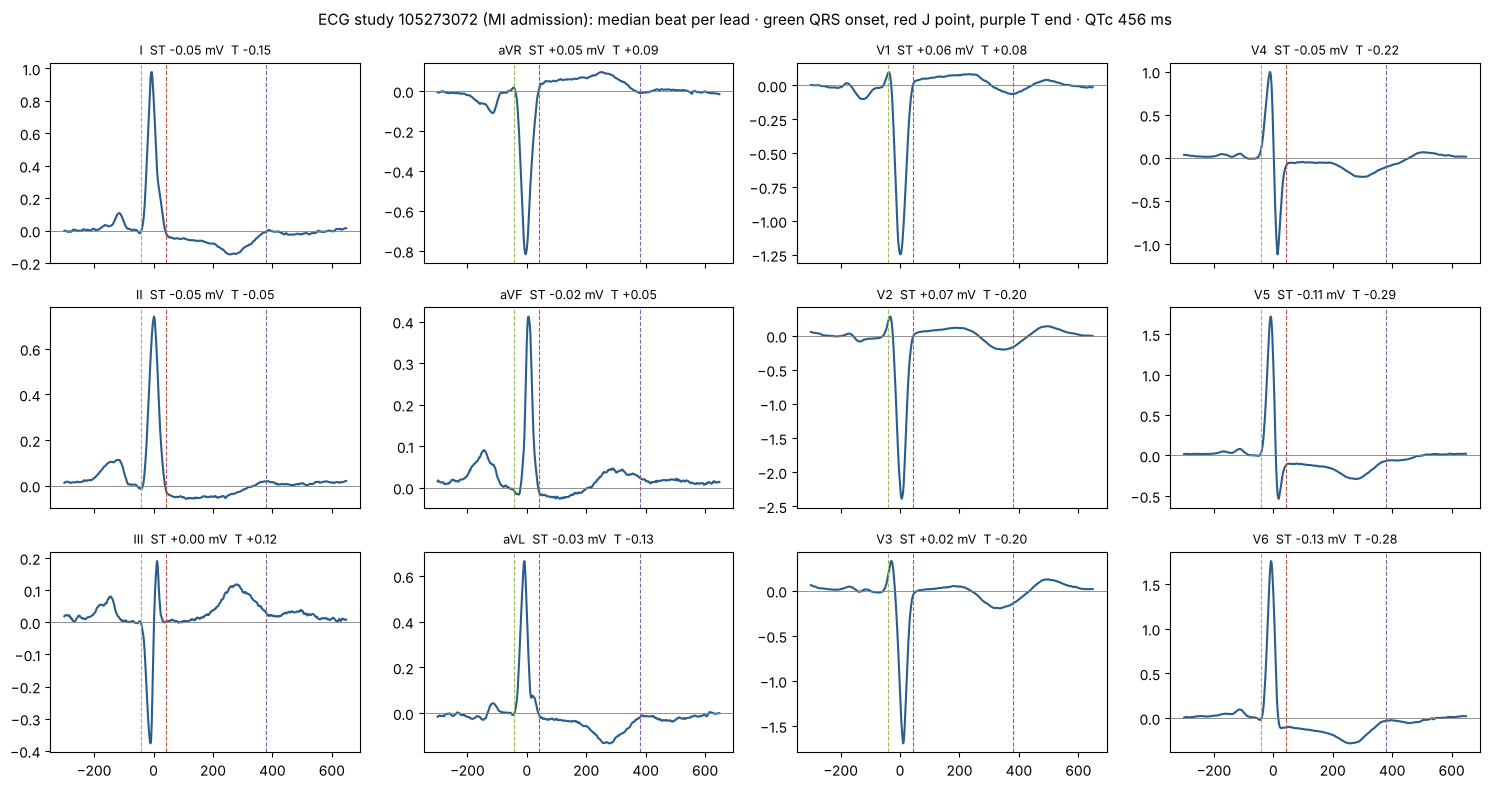

In [3]:
# sanity check against the diagnoses (the demo has no machine-read ECG reports to label against)
mi_adm = set(diagnoses[diagnoses.icd_code.astype(str).str.match(r"^(410|I21|I22)")].hadm_id)
af_adm = set(diagnoses[diagnoses.icd_code.astype(str).str.match(r"^(42731|42732|I48)")].hadm_id)
htn_adm = set(diagnoses[diagnoses.icd_code.astype(str).str.match(r"^(401|402|403|404|405|I10|I11|I12|I13|I15)")].hadm_id)
e = ecg_features[ecg_features.hadm_id.notna()].copy()
e["MI admission"], e["AF admission"], e["HTN admission"] = e.hadm_id.isin(mi_adm), e.hadm_id.isin(af_adm), e.hadm_id.isin(htn_adm)
check = pd.concat({
    "MI coded": e.groupby("MI admission")[["st_elevation", "st_depression", "t_inversion", "pathologic_q"]].mean(),
    "AF coded": e.groupby("AF admission")[["irregular_rr"]].mean(),
    "HTN coded": e.groupby("HTN admission")[["lvh_ecg"]].mean()}, axis=1).round(2)
print(check)
print("ECGs per group:", e["MI admission"].value_counts().to_dict(), e["AF admission"].value_counts().to_dict())
report["ecg_sanity"] = check.to_json()

# figure: median beats of one ECG from an MI admission with ST depression / T inversion
ex = e[e["MI admission"] & (e.st_depression == 1) & (e.t_inversion == 1)].study_id
ex = ex.iloc[0] if len(ex) else e[e["MI admission"]].study_id.iloc[0]
sig, names, fs = read_ecg(rec[rec.study_id == ex].path.iloc[0])
o = ecg_morphology(sig, names, fs, keep_beat=True)
t = (np.arange(len(o["_beat"])) - int(0.3 * fs)) / fs * 1000
fig, axes = plt.subplots(3, 4, figsize=(15, 8), sharex=True)
for ax, n in zip(axes.T.flat, names):
    j = names.index(n)
    ax.plot(t, o["_beat"][:, j], color="#2b5d8a"); ax.axhline(0, color="grey", lw=.6)
    for m, c in zip(o["_marks"], ["#9bbb59", "#c0504d", "#8064a2"]):
        ax.axvline((m - int(0.3 * fs)) / fs * 1000, color=c, ls="--", lw=.8)
    ax.set_title(f"{n}  ST {o[f'st_{n}_mv']:+.2f} mV  T {o[f't_{n}_mv']:+.2f}", fontsize=9)
fig.suptitle(f"ECG study {ex} (MI admission): median beat per lead · green QRS onset, red J point, purple T end · "
             f"QTc {o['qtc_bazett_ms']:.0f} ms", fontsize=11)
savefig("08_ecg_median_beats")

**Result:** in MI admissions, **ST depression (26% vs 11%) and T inversion (23% vs 13%)** are about twice as common, and in AF admissions **irregular RR is 48% vs 8%**. So those flags track real disease. **ST elevation (2% vs 11%) and Q waves (5% vs 16%) do not**: most MI in this demo is non-ST-elevation MI, and the simple ST-elevation rule also fires on normal variants. Treat those two as experimental. LVH is rare (2% vs 1% in hypertension admissions), as expected for Sokolow-Lyon, which catches only a minority of LVH. Saved `figures/08_ecg_median_beats.png`: an MI patient with ST depression and deep T inversion in V2-V6, I and aVL (QTc 456 ms).

# 2 · Rhythm, AF, heart-failure and night-time oxygen features (H1, H2, H6)

**What this cell does (H1 AF, H2 heart failure, H6 oxygen dips), for every ICU hour, looking back only:**
- **AF / rhythm:** hours in AF or flutter in the last 24 h (and %), **new-onset AF** (first AF hour with no AF history), brady / tachy / paced hours, number of rhythm changes, hour-to-hour HR variability.
- **Heart failure:** HR trend (last 6 h vs 18-24 h ago), **night (00-06) vs day breathing rate**, and **weight change over 72 h** from real charted daily weights. `hf_warning_count` counts HR +10 bpm, night RR +3/min and weight +2 kg in 3 days (the usual HF warning).
- **Pulse pressure** (SBP − DBP; wide means stiff arteries).
- **Oxygen dips:** hours with a measured SpO2 < 90% in the last 24 h, and at night.

In [4]:
h = dynamic_clean.sort_values(["stay_id", "hour"]).reset_index(drop=True).copy()
g = h.groupby("stay_id")
def roll(col, w, how="sum"):
    return g[col].transform(lambda x: x.rolling(w, min_periods=1).agg(how))

# H1 · AF and rhythm measures (nurse-charted rhythm, every hour)
h["af_burden_24h"] = roll("rhythm_af_flutter", 24)                     # hours in AF / flutter in the last 24 h
h["af_burden_pct_24h"] = (h.af_burden_24h / g.cumcount().add(1).clip(upper=24)).round(3)
h["af_first_hour"] = ((h.rhythm_af_flutter == 1) & (g.rhythm_af_flutter.cummax().groupby(h.stay_id).shift(1).fillna(0) == 0)).astype(int)
hist_af = h.hadm_id.map(static_clean.set_index("hadm_id").hist_af).fillna(0)
h["af_new_onset"] = ((h.af_first_hour == 1) & (hist_af == 0) & (g.cumcount() > 0)).astype(int)
h["brady_burden_24h"] = roll("rhythm_brady", 24)
h["tachy_burden_24h"] = roll("rhythm_tachy", 24)
h["paced_burden_24h"] = roll("rhythm_paced", 24)
h["rhythm_change"] = (h.rhythm_group != g.rhythm_group.shift(1)).astype(int).where(g.cumcount() > 0, 0)
h["rhythm_changes_24h"] = roll("rhythm_change", 24)
h["hr_sd_24h"] = roll("hr", 24, "std")                                  # hour-to-hour heart-rate variability

# H2 · heart-failure decompensation: rising HR, higher night breathing rate, weight gain
h["hr_trend_24h"] = roll("hr", 6, "mean") - g.hr.transform(lambda x: x.rolling(6, min_periods=1).mean().shift(18))
night, day = h.hour.dt.hour < 6, h.hour.dt.hour.between(8, 20)
h["_rr_night"], h["_rr_day"] = h.rr.where(night), h.rr.where(day)
h["rr_night_minus_day_24h"] = roll("_rr_night", 24, "mean") - roll("_rr_day", 24, "mean")

ce = ztable(zclin, "icu/chartevents.csv.gz", usecols=["stay_id", "charttime", "itemid", "valuenum"], parse_dates=["charttime"])
wt = ce[ce.itemid.isin([224639, 226512]) & ce.valuenum.between(30, 250)].rename(columns={"charttime": "t", "valuenum": "w"})
wt = wt[["stay_id", "t", "w"]].sort_values("t")
report["daily_weights"] = {"rows": len(wt), "icu_stays": int(wt.stay_id.nunique())}
h = h.sort_values("hour")
h = pd.merge_asof(h, wt.rename(columns={"t": "hour", "w": "weight_kg"}), on="hour", by="stay_id", direction="backward")
h["_h72"] = h.hour - pd.Timedelta(hours=72)
w72 = pd.merge_asof(h[["stay_id", "_h72"]].reset_index().sort_values("_h72"), wt.rename(columns={"t": "_h72", "w": "w72"}),
                    on="_h72", by="stay_id", direction="backward").set_index("index").w72
first_w = h.stay_id.map(wt.groupby("stay_id").w.first())
h["weight_change_72h"] = (h.weight_kg - w72.reindex(h.index).fillna(first_w)).round(1)
h.loc[h.weight_change_72h.abs() > 15, "weight_change_72h"] = np.nan    # > 15 kg in 3 days = charting error (e.g. lbs typed as kg)
h = h.sort_values(["stay_id", "hour"]).reset_index(drop=True)
g = h.groupby("stay_id")
h["hf_warning_count"] = ((h.hr_trend_24h >= 10).astype(int) + (h.rr_night_minus_day_24h >= 3).astype(int)
                         + (h.weight_change_72h >= 2).astype(int))      # 2 kg in 3 days = classic HF warning

# H6 · oxygen dips (hourly, measured values only)
h["pulse_pressure"] = h.sbp - h.dbp                                      # wide pulse pressure = stiff arteries
h["_dip"] = ((h.spo2 < 90) & (h.spo2_measured == 1)).astype(int)
h["spo2_dip_hours_24h"] = roll("_dip", 24)
h["_dip_night"] = h._dip.where(night, 0)
h["spo2_night_dip_hours_24h"] = roll("_dip_night", 24)
h = h.drop(columns=[c for c in h.columns if c.startswith("_")])
new_rhythm_hf = ["pulse_pressure", "af_burden_24h", "af_burden_pct_24h", "af_new_onset", "brady_burden_24h", "tachy_burden_24h", "paced_burden_24h",
                 "rhythm_changes_24h", "hr_sd_24h", "hr_trend_24h", "rr_night_minus_day_24h", "weight_kg", "weight_change_72h",
                 "hf_warning_count", "spo2_dip_hours_24h", "spo2_night_dip_hours_24h"]
print(h[new_rhythm_hf].describe().T[["count", "mean", "50%", "max"]].round(2))
print("daily weights:", report["daily_weights"])

                            count   mean    50%     max
pulse_pressure            11705.0  53.84  53.00  134.00
af_burden_24h             12015.0   4.24   0.00   24.00
af_burden_pct_24h         12015.0   0.19   0.00    1.00
af_new_onset              12015.0   0.00   0.00    1.00
brady_burden_24h          12015.0   0.72   0.00   24.00
tachy_burden_24h          12015.0   3.95   0.00   24.00
paced_burden_24h          12015.0   1.10   0.00   24.00
rhythm_changes_24h        12015.0   2.19   1.00   16.00
hr_sd_24h                 11874.0   8.26   7.24   34.72
hr_trend_24h               9592.0  -0.59  -0.50   73.92
rr_night_minus_day_24h    10847.0  -0.50  -0.50   15.50
weight_kg                 11718.0  86.95  83.40  164.00
weight_change_72h         11257.0   0.47   0.00   14.30
hf_warning_count          12015.0   0.43   0.00    3.00
spo2_dip_hours_24h        12015.0   0.18   0.00    7.00
spo2_night_dip_hours_24h  12015.0   0.02   0.00    1.00
daily weights: {'rows': 570, 'icu_stays': 137}


**Result:** 16 new hourly columns (median pulse pressure 53 mmHg). Daily weights exist for **137 ICU stays (570 values)**; jumps over 15 kg in 3 days were charting errors and are blanked. Mean AF burden is 4.2 h out of 24, and new-onset AF happens only once (most AF patients already had AF on record). 2.4% of hours have 2 or more HF warning signs, and SpO2 < 90% is rare in hourly averages.

# 3 · Medication features: QT risk, interactions and dose limits (H3, H7)

**What this cell does (H3 and medication safety):** finds the drugs **active in every ICU hour** from the real prescriptions (flushes excluded) and counts them by group: QT-prolonging (CredibleMeds known and possible risk), anticoagulants, antiplatelets, NSAIDs, ACEi/ARB, potassium-sparing diuretics, beta blockers, diltiazem/verapamil, digoxin, amiodarone and loop diuretics. Then it flags **interactions with the current orders**: bleeding (anticoagulant + antiplatelet or NSAID), **2+ QT drugs**, hyperkalaemia (ACEi/ARB + K-sparing with K > 5.0), bradycardia (beta blocker + diltiazem/verapamil/digoxin with HR < 50), digoxin + amiodarone, and two beta blockers at once. It also counts **all active drugs** (polypharmacy). It only checks what the doctor already prescribed and never suggests a drug or a dose.

In [5]:
pres = ztable(zclin, "hosp/prescriptions.csv.gz", usecols=["subject_id", "hadm_id", "starttime", "stoptime", "drug", "route"],
              parse_dates=["starttime", "stoptime"], low_memory=False)
pres = pres[~pres.drug.str.contains("flush|dwell|lock", case=False, na=False)]
GROUPS = {   # generic name keywords per group (QT lists follow CredibleMeds known / possible risk)
    "qt_known": ["amiodarone", "sotalol", "dofetilide", "haloperidol", "ondansetron", "azithromycin", "levofloxacin",
                 "ciprofloxacin", "moxifloxacin", "methadone", "citalopram", "escitalopram", "erythromycin", "fluconazole",
                 "procainamide", "chlorpromazine", "droperidol", "hydroxychloroquine"],
    "qt_possible": ["quetiapine", "olanzapine", "risperidone", "ziprasidone", "trazodone", "metoclopramide", "famotidine",
                    "tacrolimus", "prochlorperazine", "promethazine"],
    "anticoagulant": ["heparin", "warfarin", "enoxaparin", "apixaban", "rivaroxaban", "dabigatran", "argatroban", "bivalirudin"],
    "antiplatelet": ["aspirin", "clopidogrel", "prasugrel", "ticagrelor"],
    "nsaid": ["ibuprofen", "ketorolac", "naproxen", "diclofenac", "indomethacin", "celecoxib"],
    "ace_arb": ["pril", "sartan"],
    "k_sparing": ["spironolactone", "eplerenone", "amiloride", "triamterene"],
    "beta_blocker": ["metoprolol", "carvedilol", "atenolol", "labetalol", "propranolol", "esmolol", "bisoprolol", "nadolol"],
    "nondhp_ccb": ["diltiazem", "verapamil"],
    "digoxin": ["digoxin"],
    "amiodarone": ["amiodarone"],
    "loop_diuretic": ["furosemide", "torsemide", "bumetanide"],
}
def generic(drug, words):
    d = str(drug).lower()
    return next((w for w in words if w in d), None)

stay_hours = h[["stay_id", "hadm_id", "hour"]].copy()
for grp, words in GROUPS.items():
    p = pres.assign(gen=pres.drug.map(lambda d: generic(d, words))).dropna(subset=["gen"])
    j = stay_hours.reset_index().merge(p[["hadm_id", "starttime", "stoptime", "gen"]], on="hadm_id")
    j = j[(j.starttime <= j.hour) & (j.hour < j.stoptime)]
    h[f"n_{grp}"] = j.groupby("index").gen.nunique().reindex(h.index).fillna(0).astype(int)
j = stay_hours.reset_index().merge(pres[["hadm_id", "starttime", "stoptime", "drug"]], on="hadm_id")
h["n_active_drugs"] = (j[(j.starttime <= j.hour) & (j.hour < j.stoptime)].groupby("index").drug.nunique()
                       .reindex(h.index).fillna(0).astype(int))           # polypharmacy
h["n_qt_drugs"] = h.n_qt_known                                          # known-risk drugs only (Tisdale, CredibleMeds "known")

# interaction / duplicate-therapy flags against the CURRENT orders (the model never suggests a drug or dose)
k_latest = pd.merge_asof(h[["hadm_id", "hour"]].reset_index().sort_values("hour"),
                         labs[labs.item == "potassium"][["hadm_id", "time", "value"]].dropna().astype({"hadm_id": "int64"})
                         .rename(columns={"time": "hour", "value": "k"}).sort_values("hour"),
                         on="hour", by="hadm_id", direction="backward", tolerance=pd.Timedelta(hours=24)).set_index("index").k
h["potassium_latest"] = k_latest.reindex(h.index)
h["ix_bleeding"] = ((h.n_anticoagulant >= 1) & ((h.n_antiplatelet >= 1) | (h.n_nsaid >= 1))).astype(int)
h["ix_qt_combo"] = (h.n_qt_drugs >= 2).astype(int)
h["ix_hyperkalemia"] = ((h.n_ace_arb >= 1) & (h.n_k_sparing >= 1) & (h.potassium_latest > 5.0)).astype(int)
h["ix_bradycardia"] = ((h.n_beta_blocker >= 1) & ((h.n_nondhp_ccb + h.n_digoxin) >= 1) & (h.hr < 50)).astype(int)
h["ix_digoxin_amiodarone"] = ((h.n_digoxin >= 1) & (h.n_amiodarone >= 1)).astype(int)
h["dup_beta_blocker"] = (h.n_beta_blocker >= 2).astype(int)
med_cols = [c for c in h.columns if c.startswith(("n_", "ix_", "dup_"))] + ["potassium_latest"]
print(h[[c for c in med_cols if c.startswith(("ix_", "dup_"))]].mean().mul(100).round(1).rename("% of ICU hours"))
print("hours on >= 1 QT drug:", f"{(h.n_qt_drugs >= 1).mean():.1%}", "| >= 2:", f"{(h.n_qt_drugs >= 2).mean():.1%}")

ix_bleeding              17.3
ix_qt_combo              13.9
ix_hyperkalemia           0.0
ix_bradycardia            0.0
ix_digoxin_amiodarone     0.2
dup_beta_blocker          2.2
Name: % of ICU hours, dtype: float64
hours on >= 1 QT drug: 62.9% | >= 2: 13.9%


**Result:** in ICU hours, **63% have at least 1 known QT drug and 14% have 2 or more**, 17% have the bleeding combination, 2.2% have two beta blockers, and 0.2% have digoxin with amiodarone. The hyperkalaemia and bradycardia combinations never happened. A median ICU hour has 23 active drug orders.

**What this cell does (H7 dose limit):** takes every real **administered** dose from the eMAR (the nurse's administration record), adds up a **running total per drug per calendar day (resets at midnight)**, and compares it with a reference maximum daily dose (editable in `dose_limits.json`; citalopram is limited to 20 mg over age 60 because of QT risk). The hourly table gets the % of the limit used by the latest dose.

In [6]:
# H7 · dose limit check on real administrations (eMAR): total per calendar day vs a max daily dose
MAX_DAILY_MG = {   # adult reference limits; the clinic should edit these. The daily total resets at midnight
    "acetaminophen": 4000, "metoprolol": 400, "carvedilol": 100, "atenolol": 200, "labetalol": 2400, "digoxin": 1.5,
    "amiodarone": 2200, "furosemide": 600, "torsemide": 200, "lisinopril": 80, "losartan": 150, "spironolactone": 400,
    "aspirin": 4000, "clopidogrel": 600, "atorvastatin": 80, "simvastatin": 80, "rosuvastatin": 40, "diltiazem": 480,
    "verapamil": 480, "hydralazine": 300, "isosorbide mononitrate": 240, "ondansetron": 32, "citalopram": 40,
    "escitalopram": 20, "haloperidol": 30, "quetiapine": 800, "methadone": 120,
}
emar = ztable(zclin, "hosp/emar.csv.gz", parse_dates=["charttime"])
emd = ztable(zclin, "hosp/emar_detail.csv.gz", low_memory=False, usecols=["emar_id", "parent_field_ordinal", "dose_given", "dose_given_unit"])
emd = emd[emd.parent_field_ordinal.astype(str).isin(["1.1", "nan"])].dropna(subset=["dose_given"]).drop_duplicates("emar_id")
adm_ = emar[emar.event_txt == "Administered"].merge(emd, on="emar_id")
adm_["dose_mg"] = pd.to_numeric(adm_.dose_given, errors="coerce")
adm_["generic"] = adm_.medication.map(lambda d: generic(d, sorted(MAX_DAILY_MG, key=len, reverse=True)))
adm_ = adm_[adm_.generic.notna() & (adm_.dose_given_unit == "mg") & adm_.dose_mg.notna()].sort_values("charttime")
age = adm_.hadm_id.map(static_clean.set_index("hadm_id").age_at_admit)
adm_["limit_mg"] = adm_.generic.map(MAX_DAILY_MG)
adm_.loc[(adm_.generic == "citalopram") & (age > 60), "limit_mg"] = 20     # FDA QT warning: max 20 mg/day over age 60
adm_["day"] = adm_.charttime.dt.date
adm_["mg_today"] = adm_.groupby(["subject_id", "generic", "day"]).dose_mg.cumsum()     # running total, resets each day
adm_["pct_of_limit"] = (adm_.mg_today / adm_.limit_mg * 100).round(1)
adm_["over_limit"] = (adm_.mg_today > adm_.limit_mg).astype(int)
med_dose_checks = adm_[["subject_id", "hadm_id", "charttime", "medication", "generic", "dose_mg", "mg_today", "limit_mg",
                        "pct_of_limit", "over_limit"]].reset_index(drop=True)
save(med_dose_checks, "med_dose_checks")
print("administrations checked:", len(med_dose_checks), "| drugs:", med_dose_checks.generic.nunique(),
      "| over the limit:", int(med_dose_checks.over_limit.sum()), "| above 80% of the limit:", int((med_dose_checks.pct_of_limit > 80).sum()))
print(med_dose_checks[med_dose_checks.over_limit == 1].drop(columns=["subject_id"]).to_string(index=False))

# hourly: % of the daily limit used by the latest administration in the last 24 h
dc = med_dose_checks.dropna(subset=["hadm_id"]).astype({"hadm_id": "int64"}).rename(columns={"charttime": "hour"}).sort_values("hour")
h = pd.merge_asof(h.sort_values("hour"), dc[["hadm_id", "hour", "pct_of_limit"]].rename(columns={"pct_of_limit": "max_pct_dose_limit_24h"}),
                  on="hour", by="hadm_id", direction="backward", tolerance=pd.Timedelta(hours=24))
h["max_pct_dose_limit_24h"] = h.max_pct_dose_limit_24h.fillna(0)
h = h.sort_values(["stay_id", "hour"]).reset_index(drop=True)

saved features/med_dose_checks              4,289 rows x 10 cols
administrations checked: 4289 | drugs: 27 | over the limit: 3 | above 80% of the limit: 96
   hadm_id           charttime       medication       generic  dose_mg  mg_today  limit_mg  pct_of_limit  over_limit
24547356.0 2119-10-27 23:58:00 Acetaminophen IV acetaminophen   1000.0    4500.0    4000.0         112.5           1
26013492.0 2147-11-15 21:06:00     Atorvastatin  atorvastatin     80.0     160.0      80.0         200.0           1
29366372.0 2167-05-04 20:20:00     Atorvastatin  atorvastatin     80.0     120.0      80.0         150.0           1


**Result:** `features/med_dose_checks.csv`: **4,289 administrations of 27 drugs** checked. **3 went over the daily limit**: IV acetaminophen 4,500 mg (limit 4,000), and atorvastatin 160 mg and 120 mg in one day (limit 80). 96 doses were above 80% of the limit. These are real records, which is exactly what this check is for.

**What this cell does (H3 QT risk score):** joins the latest 12-lead ECG of the past 7 days to each hour (QTc, ST, T, Q flags, `hours_since_12lead`) and computes the **Tisdale score**, a validated score for drug-induced QT prolongation in hospital: age ≥ 68 (1), female (1), loop diuretic (1), K ≤ 3.5 (2), QTc ≥ 450 (2), troponin elevated (2), 1 QT drug (3), 2+ QT drugs (+3), sepsis (3; history or lactate ≥ 2 with abnormal WBC), heart failure history (3). Low ≤ 6, moderate 7-10, high ≥ 11.

In [7]:
# H3 · drug-induced QT risk: Tisdale score (validated in hospitalised patients; low <= 6, moderate 7-10, high >= 11)
sc = static_clean.set_index("hadm_id")
ecg_t = ecg_features[["subject_id", "ecg_time", "qtc_bazett_ms", "st_elevation", "st_depression", "t_inversion", "pathologic_q",
                      "qrs_ms", "irregular_rr", "lvh_ecg", "sokolow_lyon_mv"]].sort_values("ecg_time")
h = pd.merge_asof(h.sort_values("hour"), ecg_t.rename(columns={"ecg_time": "_ecg_t"}), left_on="hour", right_on="_ecg_t",
                  by="subject_id", direction="backward", tolerance=pd.Timedelta(days=7))
h["hours_since_12lead"] = (h.hour - h._ecg_t).dt.total_seconds() / 3600
h = h.drop(columns="_ecg_t").sort_values(["stay_id", "hour"]).reset_index(drop=True)
trop = clinical_clean[(clinical_clean.source == "event") & (clinical_clean.item == "troponin_elevated")]
h["troponin_elevated_so_far"] = (h.hour >= h.hadm_id.map(trop.groupby("hadm_id").time.min())).astype(int)
lw = h[["stay_id", "hour"]].merge(model_ready[["stay_id", "hour", "lab_log_lactate", "lab_log_wbc"]], how="left")
lactate, wbc = np.expm1(lw.lab_log_lactate.values), np.expm1(lw.lab_log_wbc.values)
sepsis_proxy = (lactate >= 2) & ((wbc > 12) | (wbc < 4))                  # infection + raised lactate
h["tisdale_score"] = (
    1 * (h.hadm_id.map(sc.age_at_admit) >= 68) + 1 * (h.hadm_id.map(sc.gender_male) == 0) + 1 * (h.n_loop_diuretic >= 1)
    + 2 * (h.potassium_latest <= 3.5) + 2 * (h.qtc_bazett_ms >= 450) + 2 * h.troponin_elevated_so_far
    + 3 * (h.n_qt_drugs >= 1) + 3 * (h.n_qt_drugs >= 2) + 3 * (sepsis_proxy | (h.hadm_id.map(sc.hist_sepsis) == 1))
    + 3 * (h.hadm_id.map(sc.hist_hf) == 1)).astype(int)
h["qt_risk_level"] = pd.cut(h.tisdale_score, [-1, 6, 10, 99], labels=["low", "moderate", "high"]).astype(str)
print(h.qt_risk_level.value_counts(normalize=True).mul(100).round(1).rename("% of ICU hours"))

qt_risk_level
low         60.9
moderate    31.8
high         7.2
Name: % of ICU hours, dtype: float64


**Result:** QT risk is **low in 61% of ICU hours, moderate in 32%, and high in 7%**.

# 4 · Watch / monitor warning signs (layer 2, H3, H6)

**What this cell does (layer 2 watch signs, H3, H6) on the 5-minute monitor recordings (different patients, 19 records):** personal **baseline** heart rate (expanding median) and deviation from it, **HR spikes** (+20 bpm over baseline or > 120), **SpO2 dips** (3 points below the last 30 minutes or < 90%, like an oxygen desaturation index), PVCs per minute, **monitor QTc** and **ST deviation**. Summarised per record-hour.

In [8]:
w = wearable.sort_values(["record_id", "time"]).copy()
gw = w.groupby("record_id")
w["hr_baseline"] = gw.hr.transform(lambda x: x.expanding().median())          # personal baseline so far
w["hr_vs_baseline"] = w.hr - w.hr_baseline
w["hr_spike"] = ((w.hr_vs_baseline >= 20) | (w.hr > 120)).astype(int)
w["spo2_baseline_30m"] = gw.spo2.transform(lambda x: x.rolling(6, min_periods=1).median().shift(1))
w["spo2_dip"] = ((w.spo2 <= w.spo2_baseline_30m - 3) | (w.spo2 < 90)).astype(int)   # 3-point drop, like an oxygen desaturation index
w["st_dev_mm"] = w[["st_iii_mm", "st_v_mm"]].abs().max(axis=1)
w["hour"] = w.time.dt.floor("h")
wearable_features = w.groupby(["subject_id", "record_id", "hour"]).agg(
    n_samples=("hr", "size"), hr_mean=("hr", "mean"), hr_vs_baseline=("hr_vs_baseline", "mean"), hr_spikes=("hr_spike", "sum"),
    spo2_min=("spo2", "min"), spo2_dips_per_hour=("spo2_dip", "sum"), pvc_per_min=("pvc_per_min", "mean"),
    qtc_ms=("qtc_ms", "median"), st_dev_mm_max=("st_dev_mm", "max"), perfusion_index=("perfusion_index", "mean")).reset_index()
wearable_features["frequent_pvcs"] = (wearable_features.pvc_per_min >= 6).astype(int)
wearable_features["monitor_qtc_ge_500"] = (wearable_features.qtc_ms >= 500).astype(int)
wearable_features["monitor_st_ge_1mm"] = (wearable_features.st_dev_mm_max >= 1).astype(int)
wearable_features = wearable_features.round(2)
save(wearable_features, "wearable_features")
print(wearable_features.describe().T[["count", "mean", "50%", "max"]].round(1).iloc[3:])

saved features/wearable_features               93 rows x 16 cols
                   count        mean     50%    max
n_samples           93.0    9.623656    12.0   12.0
hr_mean             92.0   89.053587   79.98  165.0
hr_vs_baseline      92.0    0.652283    0.02  14.94
hr_spikes           93.0    1.537634     0.0   12.0
spo2_min            93.0    95.24871   95.58  100.0
spo2_dips_per_hour  93.0    0.354839     0.0    4.0
pvc_per_min         82.0    0.786707    0.29   4.72
qtc_ms              65.0  478.324462  465.28  729.0
st_dev_mm_max       78.0    0.721795   0.515   2.81
perfusion_index     54.0    1.642222   0.985   4.46
frequent_pvcs       93.0         0.0     0.0    0.0
monitor_qtc_ge_500  93.0    0.204301     0.0    1.0
monitor_st_ge_1mm   93.0    0.193548     0.0    1.0


**Result:** `features/wearable_features.csv`: **93 record-hours**. Median monitor QTc 465 ms (20% of hours ≥ 500), ST deviation ≥ 1 mm in 19% of hours, up to 4 SpO2 dips per hour, and no hour with frequent PVCs (≥ 6/min). These are real monitor values, used to set the watch thresholds and replay the watch stream in the demo. Steps, activity and HR recovery are not in any dataset.

# 5 · Admission-level risk scores: CAD risk (layer 1), stroke and bleeding (H1), troponin (layer 5)

**What this cell does (layer 1 CAD risk, H1 stroke and bleeding, layer 5 troponin), one row per admission:**
1. Risk factors **known before this admission** (codes from earlier admissions only: `smoker_prior`, `fam_hx_cad_prior`, ...), so the CAD label cannot leak in.
   Plus extra history from ICD codes: **peripheral artery disease, COPD, sleep apnoea, alcohol use, valve disease, cardiomyopathy, pacemaker/ICD, anaemia**.
2. Latest real **total cholesterol, HDL, LDL, triglycerides, non-HDL, TC/HDL ratio and HbA1c** up to discharge (outpatient values included), first creatinine, and **eGFR** (CKD-EPI 2021).
3. **ASCVD Pooled Cohort Equations** 10-year risk (2013 ACC/AHA; age clipped to 40-79, cohort median lipids where never measured, flagged by `lipids_measured`).
4. **CHA2DS2-VASc** (stroke risk in AF) and **HAS-BLED (partial)**: liver disease, bleeding history, labile INR and alcohol are not available.
5. **Troponin T** max and rise, giving `mi_confirmed_troponin`, plus the labels `label_cad` (ICD I20-I25 / 410-414) and `label_mi`.
6. `lpa_mg_dl` and `polygenic_score` are **empty columns for the user to enter in the app**. They are not in any dataset and are not invented.

In [9]:
a = static_clean.sort_values(["subject_id", "admittime"]).copy()
# risk factors known BEFORE this admission (codes from earlier admissions only), so the CAD label can't leak in
code_ = diagnoses.icd_code.astype(str).str.strip()
RISK = {"smoker": r"^(3051|V1582|F17|Z87891|Z720)", "fam_hx_cad": r"^(V173|V174|Z8249|Z824)",
        "hyperlipidemia": r"^(2720|2721|2722|2724|E78)", "prior_mi_or_revasc": r"^(412|V4581|V4582|Z951|Z955|I252)",
        "pad": r"^(4439|4402|I739|I702)", "copd": r"^(491|492|496|J41|J42|J43|J44)", "sleep_apnea": r"^(32723|78057|G4733)",
        "alcohol_use": r"^(303|3050|F10)", "valve_disease": r"^(424|394|395|396|397|I05|I06|I07|I08|I34|I35|I36|I37)",
        "cardiomyopathy": r"^(425|I42|I43)", "cardiac_device": r"^(V450|Z950|Z9581)", "anemia_dx": r"^(280|281|285|D50|D51|D52|D53|D63|D64)"}
f = pd.DataFrame({k: code_.str.match(p).astype(int) for k, p in RISK.items()}).assign(hadm_id=diagnoses.hadm_id).groupby("hadm_id").max()
a = a.drop(columns=[k for k in RISK if k in a]).merge(f, left_on="hadm_id", right_index=True, how="left").fillna({k: 0 for k in RISK})
for k in RISK:
    a[f"{k}_prior"] = a.groupby("subject_id")[k].transform(lambda x: x.cummax().shift(1)).fillna(0).astype(int)
    a[f"hx_{k}"] = a.groupby("subject_id")[k].cummax().astype(int)         # this or an earlier admission (for the hourly model)

# labs at this admission: first creatinine (eGFR), latest lipids and HbA1c up to discharge (incl. outpatient)
lab_all = labs.dropna(subset=["value"]).sort_values("time")
def latest_before(item, col):
    l = lab_all[lab_all.item == item][["subject_id", "time", "value"]].rename(columns={"time": "dischtime", "value": col})
    return pd.merge_asof(a[["subject_id", "dischtime"]].reset_index().sort_values("dischtime"), l, on="dischtime",
                         by="subject_id", direction="backward").set_index("index")[col]
for item, col in [("chol_total", "total_chol"), ("hdl", "hdl"), ("ldl", "ldl"), ("triglycerides", "triglycerides"), ("hba1c", "hba1c")]:
    a[col] = latest_before(item, col)
a["non_hdl"] = a.total_chol - a.hdl
a["tc_hdl_ratio"] = (a.total_chol / a.hdl).round(2)
cr = lab_all[(lab_all.item == "creatinine") & lab_all.hadm_id.notna()].groupby("hadm_id").value.first()
a["creatinine_first"] = a.hadm_id.map(cr)
# eGFR, CKD-EPI 2021 (race-free)
fem = a.gender_male == 0
k_, al = np.where(fem, 0.7, 0.9), np.where(fem, -0.241, -0.302)
scr = a.creatinine_first / k_
a["egfr"] = (142 * np.minimum(scr, 1) ** al * np.maximum(scr, 1) ** -1.2 * 0.9938 ** a.age_at_admit * np.where(fem, 1.012, 1)).round(1)
a["diabetes"] = ((a.hist_dm == 1) | (a.hba1c >= 6.5)).astype(int)
a["ckd"] = ((a.hist_ckd == 1) | (a.egfr < 60)).astype(int)
a["lipids_measured"] = a.total_chol.notna() & a.hdl.notna()

# ASCVD Pooled Cohort Equations (2013 ACC/AHA), 10-year risk; valid for age 40-79
PCE = {  # (ln age, ln age², ln TC, ln age·ln TC, ln HDL, ln age·ln HDL, ln trSBP, ln age·ln trSBP, ln utSBP, ln age·ln utSBP, smoker, ln age·smoker, DM, S0, mean)
    ("F", "white"): (-29.799, 4.884, 13.540, -3.114, -13.578, 3.149, 2.019, 0, 1.957, 0, 7.574, -1.665, 0.661, 0.9665, -29.18),
    ("F", "black"): (17.114, 0, 0.940, 0, -18.920, 4.475, 29.291, -6.432, 27.820, -6.087, 0.691, 0, 0.874, 0.9533, 86.61),
    ("M", "white"): (12.344, 0, 11.853, -2.664, -7.990, 1.769, 1.797, 0, 1.764, 0, 7.837, -1.795, 0.658, 0.9144, 61.18),
    ("M", "black"): (2.469, 0, 0.302, 0, -0.307, 0, 1.916, 0, 1.809, 0, 0.549, 0, 0.645, 0.8954, 19.54)}
TC_MED, HDL_MED = a.total_chol.median(), a.hdl.median()                      # only used when lipids were never measured
def pce(r):
    c = PCE[("F" if r.gender_male == 0 else "M", "black" if r.race == "BLACK" else "white")]
    la, tc, hdl = np.log(np.clip(r.age_at_admit, 40, 79)), np.log(r.total_chol if r.total_chol == r.total_chol else TC_MED), \
                  np.log(r.hdl if r.hdl == r.hdl else HDL_MED)
    sbp, tr = np.log(r.sbp_outpatient), r.hist_htn == 1                       # treated BP: hypertension on record
    s = (c[0] * la + c[1] * la ** 2 + c[2] * tc + c[3] * la * tc + c[4] * hdl + c[5] * la * hdl
         + (c[6] * sbp + c[7] * la * sbp if tr else c[8] * sbp + c[9] * la * sbp)
         + c[10] * r.smoker_prior + c[11] * la * r.smoker_prior + c[12] * r.diabetes)
    return 1 - c[13] ** np.exp(s - c[14])
a["ascvd_10y_risk"] = a.apply(pce, axis=1).round(3)
a["ascvd_age_in_range"] = a.age_at_admit.between(40, 79).astype(int)
a["lpa_mg_dl"], a["polygenic_score"] = np.nan, np.nan                        # not in any dataset: entered in the app, never invented

# H1 · stroke risk in AF (CHA2DS2-VASc) and bleeding risk (HAS-BLED, partial: liver, bleeding history, INR, alcohol unknown)
vasc = ((a.hist_mi == 1) | (a.hist_cad == 1) | (a.prior_mi_or_revasc_prior == 1)).astype(int)
a["cha2ds2_vasc"] = (a.hist_hf + a.hist_htn + 2 * (a.age_at_admit >= 75) + a.hist_dm + 2 * a.hist_stroke + vasc
                     + a.age_at_admit.between(65, 74) + (a.gender_male == 0)).astype(int)
a["has_bled_partial"] = (a.hist_htn + ((a.hist_ckd == 1) | (a.creatinine_first >= 2.26)) + a.hist_stroke
                         + (a.age_at_admit > 65) + a.alcohol_use_prior).astype(int)

# layer 5 · troponin T confirmation (real labs) and the CAD label from ICD codes I20-I25 / 410-414
tt = lab_all[(lab_all.item == "troponin_t") & lab_all.hadm_id.notna()]
a["troponin_t_max"] = a.hadm_id.map(tt.groupby("hadm_id").value.max())
a["troponin_rise"] = a.hadm_id.map(tt.groupby("hadm_id").value.apply(lambda s: int(len(s) > 1 and s.diff().max() > 0)))
a["mi_confirmed_troponin"] = ((a.troponin_t_max > 0.01) & (a.troponin_rise == 1)).astype(int)
a["label_cad"] = a.dx_cad.astype(int)
a["label_mi"] = a.dx_mi.astype(int)

CAD_COLS = ["subject_id", "hadm_id", "admittime", "age_at_admit", "gender_male", "race", "bmi", "sbp_outpatient", "dbp_outpatient",
            "total_chol", "hdl", "ldl", "triglycerides", "non_hdl", "tc_hdl_ratio", "hba1c", "lipids_measured", "creatinine_first", "egfr", "diabetes", "ckd", "hist_htn", "hist_cad", "hist_mi",
            "hist_hf", "hist_stroke", "smoker_prior", "fam_hx_cad_prior", "hyperlipidemia_prior", "prior_mi_or_revasc_prior",
            "pad_prior", "copd_prior", "sleep_apnea_prior", "alcohol_use_prior", "valve_disease_prior", "cardiomyopathy_prior",
            "cardiac_device_prior", "anemia_dx_prior",
            "lpa_mg_dl", "polygenic_score", "ascvd_10y_risk", "ascvd_age_in_range", "cha2ds2_vasc", "has_bled_partial",
            "troponin_t_max", "troponin_rise", "mi_confirmed_troponin", "label_cad", "label_mi"]
cad_risk_table = a[CAD_COLS].reset_index(drop=True)
HX_NEW = ["hx_pad", "hx_copd", "hx_sleep_apnea", "hx_alcohol_use", "hx_valve_disease", "hx_cardiomyopathy", "hx_cardiac_device", "hx_anemia_dx"]
hx_table = a[["hadm_id"] + HX_NEW]
print("patients with each extra history item:", {k: int(a.groupby("subject_id")[k].max().sum()) for k in HX_NEW})
save(cad_risk_table, "cad_risk_table")

def auroc(y, s):
    ok = s.notna(); y, s = y[ok], s[ok].rank()
    n1, n0 = y.sum(), (1 - y).sum()
    return (s[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
report["cad_baseline"] = {"admissions": len(a), "cad_label_rate": round(a.label_cad.mean(), 3),
                          "lipids_measured": int(a.lipids_measured.sum()),
                          "auroc_ascvd_vs_cad_dx": round(auroc(a.label_cad, a.ascvd_10y_risk), 3),
                          "mi_coded": int(a.label_mi.sum()), "mi_confirmed_by_troponin": int(a.mi_confirmed_troponin.sum()),
                          "both": int((a.label_mi & a.mi_confirmed_troponin).sum())}
print(report["cad_baseline"])
print(a[["ascvd_10y_risk", "cha2ds2_vasc", "has_bled_partial", "egfr"]].describe().round(2).T[["count", "mean", "50%", "max"]])

patients with each extra history item: {'hx_pad': 4, 'hx_copd': 14, 'hx_sleep_apnea': 9, 'hx_alcohol_use': 23, 'hx_valve_disease': 15, 'hx_cardiomyopathy': 4, 'hx_cardiac_device': 6, 'hx_anemia_dx': 40}
saved features/cad_risk_table                 275 rows x 49 cols
{'admissions': 275, 'cad_label_rate': np.float64(0.295), 'lipids_measured': 107, 'auroc_ascvd_vs_cad_dx': np.float64(0.667), 'mi_coded': 12, 'mi_confirmed_by_troponin': 17, 'both': 6}
                  count   mean    50%     max
ascvd_10y_risk    275.0   0.19   0.14    0.63
cha2ds2_vasc      275.0   2.36   2.00    7.00
has_bled_partial  275.0   1.33   1.00    4.00
egfr              250.0  73.33  80.40  150.20


**Result:** `features/cad_risk_table.csv`: **275 admissions × 49 columns**. CAD is coded in **29.5%** of admissions, and lipids were measured for 107. The published **ASCVD score alone gives AUROC 0.667** for the CAD diagnosis: this is the baseline the LightGBM model has to beat. Median 10-year risk is 14%, median CHA2DS2-VASc 2 (max 7), and median eGFR 80. MI is coded in 12 admissions and troponin-confirmed in 17, with 6 overlapping. Patients with the extra history items: anaemia 40, alcohol 23, valve disease 15, COPD 14, sleep apnoea 9, pacemaker/ICD 6, PAD 4, cardiomyopathy 4. HAS-BLED now includes alcohol.

# 6 · Join everything into the model table

**What this cell does:** joins the new hourly features, the latest-ECG flags, the medication flags and the admission scores onto `model_ready` (same rows, same train/test split), saves `model_features.csv`, and writes `features_config.json` (the full feature list plus train-only scaling values for the new columns). Then it checks how often each new flag is followed by deterioration within 6 h on the **train** rows.

saved features/hourly_cardiac_features     12,015 rows x 70 cols


saved features/model_features               4,503 rows x 219 cols
model_ready (4503, 154) -> model_features (4503, 219): 65 new features, 211 in total
                              % of hours  event rate if yes %  \
QTc >= 500 ms                        5.3                  8.3   
ST depression (12-lead)              5.2                  6.2   
T inversion (12-lead)                7.1                  4.5   
>= 2 QT drugs                       11.2                  2.4   
CHA2DS2-VASc >= 4                   22.3                  2.0   
QT risk high (Tisdale >= 11)         3.6                  1.6   
SpO2 < 90% >= 2 h/24 h               2.0                  1.4   
AF burden >= 12 h/24 h               1.5                  0.0   
HF warning signs >= 2                2.4                  0.0   
Bleeding combo                      15.1                  0.0   

                              event rate if no %  hours  
QTc >= 500 ms                                1.9    181  
ST depression (12

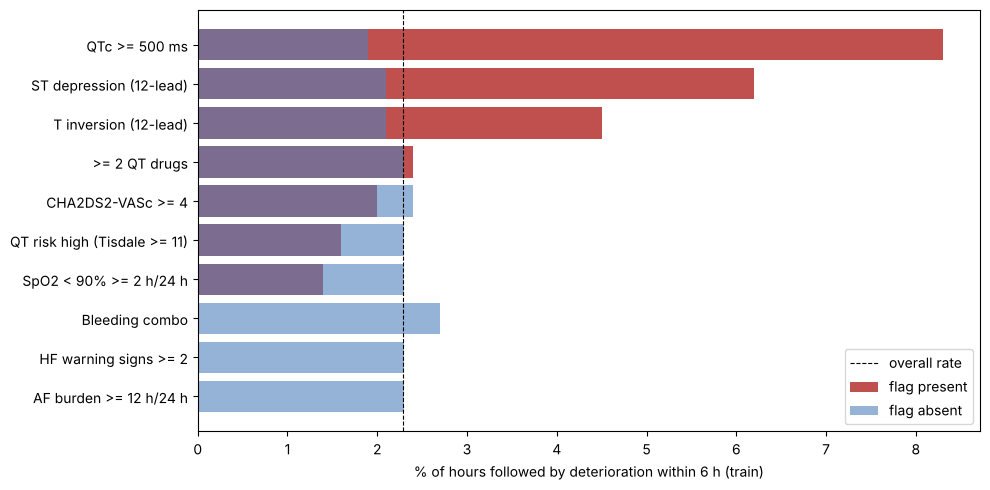

In [10]:
SCORES = ["cha2ds2_vasc", "has_bled_partial", "egfr", "ascvd_10y_risk", "diabetes", "ckd", "total_chol", "hdl", "ldl",
          "triglycerides", "non_hdl", "tc_hdl_ratio", "hba1c", "sbp_outpatient", "dbp_outpatient"] + HX_NEW
h = h.merge(cad_risk_table[["hadm_id"] + SCORES[:-len(HX_NEW)]].merge(hx_table, on="hadm_id"), on="hadm_id", how="left")
ECG_NEW = ["qtc_bazett_ms", "qrs_ms", "st_elevation", "st_depression", "t_inversion", "pathologic_q", "irregular_rr", "lvh_ecg",
           "sokolow_lyon_mv", "hours_since_12lead"]
MED_NEW = ["n_active_drugs", "n_qt_drugs", "n_qt_known", "n_anticoagulant", "n_antiplatelet", "n_beta_blocker", "n_loop_diuretic", "ix_bleeding",
           "ix_qt_combo", "ix_hyperkalemia", "ix_bradycardia", "ix_digoxin_amiodarone", "dup_beta_blocker", "max_pct_dose_limit_24h",
           "tisdale_score", "troponin_elevated_so_far"]
NEW = new_rhythm_hf + ECG_NEW + MED_NEW + SCORES
hourly = h[["subject_id", "hadm_id", "stay_id", "hour"] + NEW + ["qt_risk_level"]]
save(hourly, "hourly_cardiac_features")

model_features = model_ready.merge(hourly[["stay_id", "hour"] + NEW], on=["stay_id", "hour"], how="left")
assert len(model_features) == len(model_ready)
features = config["features"] + [c for c in NEW if c not in config["features"]]
tr = model_features[model_features.split == "train"]
fconf = dict(config, features=features, new_cardiac_features=NEW,
             scaler={**config["scaler"], **{c: (float(tr[c].mean()), float(tr[c].std()) or 1.0)
                                            for c in NEW if tr[c].nunique() > 2}})
save(model_features, "model_features")
(FEAT / "features_config.json").write_text(json.dumps(fconf, indent=1))
print(f"model_ready {model_ready.shape} -> model_features {model_features.shape}: {len(NEW)} new features, {len(features)} in total")

# how each new flag relates to deterioration in the next 6 h (train rows)
flags = {"AF new onset": tr.af_new_onset == 1, "AF burden >= 12 h/24 h": tr.af_burden_24h >= 12,
         "HF warning signs >= 2": tr.hf_warning_count >= 2, "SpO2 < 90% >= 2 h/24 h": tr.spo2_dip_hours_24h >= 2,
         "ST depression (12-lead)": tr.st_depression == 1, "T inversion (12-lead)": tr.t_inversion == 1,
         "QTc >= 500 ms": tr.qtc_bazett_ms >= 500, "QT risk high (Tisdale >= 11)": tr.tisdale_score >= 11,
         "Bleeding combo": tr.ix_bleeding == 1, ">= 2 QT drugs": tr.ix_qt_combo == 1, "CHA2DS2-VASc >= 4": tr.cha2ds2_vasc >= 4}
lift = pd.DataFrame({k: {"% of hours": v.mean() * 100, "event rate if yes %": tr.label_6h[v].mean() * 100,
                         "event rate if no %": tr.label_6h[~v].mean() * 100} for k, v in flags.items()}).T.round(1)
lift["hours"] = [int(v.sum()) for v in flags.values()]
lift = lift[lift.hours >= 20]                                              # too few hours to say anything
print(lift.sort_values("event rate if yes %", ascending=False))
fig, ax = plt.subplots(figsize=(10, 5))
l = lift.sort_values("event rate if yes %")
ax.barh(l.index, l["event rate if yes %"], color="#c0504d", label="flag present")
ax.barh(l.index, l["event rate if no %"], color="#4f81bd", alpha=.6, label="flag absent")
ax.axvline(tr.label_6h.mean() * 100, color="k", ls="--", lw=.8, label="overall rate")
ax.set_xlabel("% of hours followed by deterioration within 6 h (train)"); ax.legend()
savefig("09_new_feature_event_rates")

**Result:** `features/model_features.csv`: **4,503 hours × 219 columns, 65 new features (211 in total)**. Compared with the 2.3% base rate, deterioration within 6 h is **8.3% when QTc ≥ 500, 6.2% with ST depression, and 4.5% with T inversion** on the latest 12-lead. That is 2 to 4 times higher. The others (AF burden, HF signs, bleeding combination) are about the base rate or below for short-term deterioration; they matter for the stroke, HF and safety use cases, not this label. Saved `figures/09_new_feature_event_rates.png`.

# 7 · Tiered alerts and the alert-rate budget

**What this cell does (tiered alerts and the alert-rate budget):** defines **red** and **amber** rules, replays them over every real ICU hour with a **snooze** (the same alert re-fires only after 4 h for red, 8 h for amber), and measures **alerts per patient-day** and the **% of alerts followed by deterioration within 6 h**. The routing is saved too: red pages the doctor (acknowledge, snooze with a reason, audit log), and the patient sees "contact your care team" plus a one-tap Call 108. The model **never calls an ambulance or suggests a drug** on its own.

 tier                              rule  alerts   ppv  per_patient_day
  red                         NEWS >= 7     262   5.7             1.40
  red    Shock index >= 1 with SBP < 90      54  18.5             0.29
  red        QTc >= 500 ms on a QT drug      26   7.7             0.14
  red                        SpO2 < 88%      11   0.0             0.06
amber                          NEWS 5-6     316   4.4             1.68
amber                 Medication safety      99   2.0             0.53
amber      QT risk high (Tisdale >= 11)      26   3.8             0.14
amber             HF warning signs >= 2      25   4.0             0.13
amber ST / T change on 12-lead (<= 6 h)      21  19.0             0.11
amber             SpO2 < 90% for >= 2 h      18   5.6             0.10
amber                            New AF       1 100.0             0.01
       alerts  ppv  per_patient_day
tier                               
amber     506  4.7             2.70
red       353  7.6             1.88
base

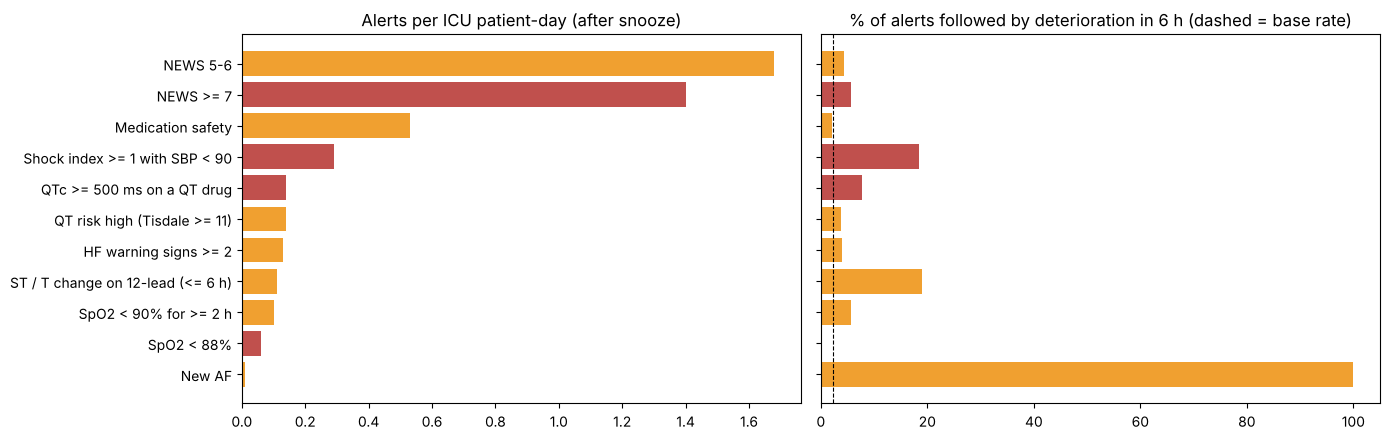

In [11]:
ALERT_RULES = {
    "red": {
        "NEWS >= 7":                       "news_score >= 7",
        "Shock index >= 1 with SBP < 90":  "shock_index >= 1 and sbp < 90",
        "ST elevation + troponin up":      "st_elevation == 1 and hours_since_12lead <= 6 and troponin_elevated_so_far == 1",
        "QTc >= 500 ms on a QT drug":      "qtc_bazett_ms >= 500 and n_qt_drugs >= 1",
        "SpO2 < 88%":                      "spo2 < 88",
    },
    "amber": {
        "NEWS 5-6":                        "news_score >= 5 and news_score < 7",
        "New AF":                          "af_new_onset == 1",
        "ST / T change on 12-lead (<= 6 h)": "(st_elevation == 1 or st_depression == 1 or t_inversion == 1) and hours_since_12lead <= 6",
        "HF warning signs >= 2":           "hf_warning_count >= 2",
        "QT risk high (Tisdale >= 11)":    "tisdale_score >= 11",
        "Medication safety":               "ix_bleeding == 1 or ix_hyperkalemia == 1 or ix_bradycardia == 1 or max_pct_dose_limit_24h > 100",
        "SpO2 < 90% for >= 2 h":           "spo2_dip_hours_24h >= 2",
    },
}
SNOOZE_H = {"red": 4, "amber": 8}   # the same alert re-fires only after the snooze (alarm-fatigue control)

def fire_alerts(df):
    df = df.sort_values(["stay_id", "hour"])
    out = []
    for tier, rules in ALERT_RULES.items():
        for name, cond in rules.items():
            hit = df.query(cond)[["subject_id", "stay_id", "hour", "label_6h"]]
            last = {}
            for r in hit.itertuples():
                if r.stay_id not in last or (r.hour - last[r.stay_id]).total_seconds() / 3600 >= SNOOZE_H[tier]:
                    out.append((r.subject_id, r.stay_id, r.hour, tier, name, r.label_6h)); last[r.stay_id] = r.hour
    return pd.DataFrame(out, columns=["subject_id", "stay_id", "hour", "tier", "rule", "event_within_6h"])

alerts = fire_alerts(model_features)
patient_days = len(model_features) / 24
budget = alerts.groupby(["tier", "rule"]).agg(alerts=("rule", "size"), ppv=("event_within_6h", "mean")).reset_index()
budget["per_patient_day"] = (budget.alerts / patient_days).round(2)
budget["ppv"] = budget.ppv.mul(100).round(1)
tiers = alerts.groupby("tier").agg(alerts=("rule", "size"), ppv=("event_within_6h", "mean"))
tiers["per_patient_day"], tiers["ppv"] = (tiers.alerts / patient_days).round(2), tiers.ppv.mul(100).round(1)
ev_hours = model_features[model_features.label_6h == 1][["stay_id", "hour"]]
caught = ev_hours.merge(alerts[alerts.tier == "red"][["stay_id", "hour"]], on=["stay_id", "hour"]).drop_duplicates()
print(budget.sort_values(["tier", "alerts"], ascending=[False, False]).to_string(index=False))
print(tiers)
print(f"base rate (any hour): {model_features.label_6h.mean():.1%} | ICU patient-days: {patient_days:.0f}")
save(alerts, "alert_log")
(FEAT / "alert_rules.json").write_text(json.dumps({
    "rules": ALERT_RULES, "snooze_hours": SNOOZE_H, "budget_per_patient_day": tiers.per_patient_day.to_dict(),
    "routing": {"red": "doctor inbox (page) with acknowledge / snooze-with-reason, audit log; patient sees 'contact your care team' and a one-tap Call 108",
                "amber": "doctor inbox (no page); caregiver notified if consented; patient sees a soft check-in"},
    "never_automatic": ["calling an ambulance", "suggesting a new drug or dose"]}, indent=1))
report["alerts"] = tiers.reset_index().to_dict("records")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
b = budget.sort_values("per_patient_day")
axes[0].barh(b.rule, b.per_patient_day, color=b.tier.map({"red": "#c0504d", "amber": "#f0a030"}))
axes[0].set_title("Alerts per ICU patient-day (after snooze)")
axes[1].barh(b.rule, b.ppv, color=b.tier.map({"red": "#c0504d", "amber": "#f0a030"}))
axes[1].axvline(model_features.label_6h.mean() * 100, color="k", ls="--", lw=.8)
axes[1].set_title("% of alerts followed by deterioration in 6 h (dashed = base rate)"); axes[1].set_yticklabels([])
savefig("10_alert_budget")

**Result:** about **1.9 red and 2.7 amber alerts per ICU patient-day**. Red alerts are followed by deterioration **7.6%** of the time, 3.3 times the 2.3% base rate. The most useful rules are **shock index ≥ 1 with SBP < 90 (18.5%)** and **ST/T change on a recent 12-lead (19%)**. NEWS ≥ 7 is the noisiest (1.4 per patient-day, 5.7%), so the trained model should replace it as the main red trigger. Saved `alert_rules.json`, `features/alert_log.csv` (859 alerts) and `figures/10_alert_budget.png`.

# 8 · Rule functions for the app (`twin_rules.py`)

**What this cell does:** writes **`Happiest_Health/twin_rules.py`**, the rule functions the app calls: `alert_tier()` (uses `alert_rules.json`), `symptom_check()` (chatbot checklist: chest pain, spreading pain, breathlessness, cold sweat, nausea, dizziness), `safe_exercise_zone()` (Karvonen; beta-blocker-aware HRmax), `hr_recovery_flag()` (< 12 bpm after 1 minute is abnormal) and `dose_check()`. Then it tests each one.

In [12]:
RULES_MODULE = """
# Rule functions for the digital-twin app. Not trained models: transparent rules with sources.
import json

def alert_tier(row, rules):
    # row: dict of the latest hourly features; rules: alert_rules.json["rules"]
    for tier in ("red", "amber"):
        hits = [name for name, cond in rules[tier].items() if _eval(cond, row)]
        if hits:
            return tier, hits
    return "green", []

def _eval(cond, row):
    try:
        return bool(eval(cond, {"__builtins__": {}}, {k: (v if v == v else float("nan")) for k, v in row.items()}))
    except Exception:
        return False

SYMPTOMS = {"chest_pain": 3, "pain_spreads_arm_jaw_back": 2, "breathless": 2, "cold_sweat": 2, "nausea": 1, "dizzy_or_fainted": 2}

def symptom_check(answers):
    # answers from the chatbot, e.g. {"chest_pain": True, "cold_sweat": True}; a triage aid, not a diagnosis
    score = sum(w for k, w in SYMPTOMS.items() if answers.get(k))
    urgent = answers.get("chest_pain") and (answers.get("pain_spreads_arm_jaw_back") or answers.get("cold_sweat") or answers.get("breathless"))
    return {"score": score, "tier": "red" if urgent or score >= 6 else "amber" if score >= 3 else "green"}

def safe_exercise_zone(age, resting_hr, on_beta_blocker=False, low=0.4, high=0.6):
    # Karvonen heart-rate reserve; on beta blockers HRmax = 164 - 0.7 x age (Brawner 2004), else 220 - age
    hr_max = 164 - 0.7 * age if on_beta_blocker else 220 - age
    reserve = hr_max - resting_hr
    return {"hr_max": round(hr_max), "zone": (round(resting_hr + low * reserve), round(resting_hr + high * reserve))}

def hr_recovery_flag(hr_peak, hr_after_1_min):
    # heart-rate recovery < 12 bpm after 1 minute is abnormal (Cole 1999)
    return int(hr_peak - hr_after_1_min < 12)

def dose_check(generic, mg_today, limits, age=None):
    # compares today's total of a prescribed drug with the clinic's daily limit (resets at midnight); never suggests a new dose
    limit = limits.get(generic)
    if generic == "citalopram" and age and age > 60:
        limit = 20
    if limit is None:
        return {"status": "no limit on file"}
    pct = 100 * mg_today / limit
    return {"pct_of_limit": round(pct), "status": "over limit: tell the doctor" if pct > 100 else "near limit" if pct > 80 else "ok"}
"""
(ROOT / "twin_rules.py").write_text(RULES_MODULE.lstrip())
(FEAT / "dose_limits.json").write_text(json.dumps(MAX_DAILY_MG, indent=1))
import importlib, sys
sys.path[:0] = [str(ROOT.resolve()), str((ROOT / "src").resolve())]
import twin_rules as tr_
importlib.reload(tr_)
rules = json.loads((FEAT / "alert_rules.json").read_text())["rules"]
example = model_features[model_features.label_6h == 1].iloc[0].to_dict()
print("alert tier of a real pre-event hour:", tr_.alert_tier(example, rules))
print("symptoms:", tr_.symptom_check({"chest_pain": True, "cold_sweat": True}))
print("exercise zone, age 62, resting HR 70, on beta blocker:", tr_.safe_exercise_zone(62, 70, True))
print("HR recovery 128 -> 120 bpm:", "abnormal" if tr_.hr_recovery_flag(128, 120) else "normal")
print("dose check, metoprolol 450 mg today:", tr_.dose_check("metoprolol", 450, MAX_DAILY_MG))
(FEAT / "feature_report.json").write_text(json.dumps(report, indent=2, default=str))
print("\nfeatures/:", sorted(p.name for p in FEAT.glob("*.csv")))
print("figures/ :", sorted(p.name for p in FIG.glob("*.png")))

alert tier of a real pre-event hour: ('amber', ['NEWS 5-6'])
symptoms: {'score': 5, 'tier': 'red'}
exercise zone, age 62, resting HR 70, on beta blocker: {'hr_max': 121, 'zone': (90, 100)}
HR recovery 128 -> 120 bpm: abnormal
dose check, metoprolol 450 mg today: {'pct_of_limit': 112, 'status': 'over limit: tell the doctor'}

features/: ['alert_log.csv', 'cad_risk_table.csv', 'ecg_features.csv', 'hourly_cardiac_features.csv', 'med_dose_checks.csv', 'model_features.csv', 'wearable_features.csv']
figures/ : ['08_ecg_median_beats.png', '09_new_feature_event_rates.png', '10_alert_budget.png']


**Result:** a real pre-event hour comes out **amber (NEWS 5-6)**. Chest pain with cold sweat gives **red**. Age 62, resting HR 70, on a beta blocker gives an exercise zone of **90-100 bpm**. A drop from 128 to 120 bpm after 1 minute is **abnormal** recovery, and metoprolol 450 mg in a day is **112% of the limit, so tell the doctor**. All outputs are listed.

# 9 · Cardiovascular risk feature checklist

✅ = already in `03_feature_engineering.ipynb` (computed from real data) · ⬜ = not in any of our datasets, so it comes from the app, the watch or the user (never invented)

## A. Patient history and risk factors (static)

| Feature | Why it matters | Status | Column(s) |
|---|---|---|---|
| Age, sex | Strongest non-modifiable risk factors | ✅ | `age_at_admit`, `gender_male` |
| Smoking | Doubles heart-attack risk | ✅ | `smoker` (ICD codes), `smoker_prior` |
| Smoking pack-years / quit date | Dose of exposure | ⬜ | App question |
| Hypertension | Main driver of CAD, stroke and HF | ✅ | `hist_htn`, outpatient `sbp_outpatient`, `dbp_outpatient` |
| Diabetes | 2-4x CAD risk | ✅ | `diabetes` (history or HbA1c ≥ 6.5), `hba1c` |
| Cholesterol: total, LDL, HDL, triglycerides | Causal for atherosclerosis | ✅ | `total_chol`, `ldl`, `hdl`, `triglycerides` |
| Non-HDL cholesterol, TC/HDL ratio | Better risk markers than LDL alone | ✅ | `non_hdl`, `tc_hdl_ratio` |
| Hyperlipidaemia diagnosis | Treated / known high cholesterol | ✅ | `hyperlipidemia` |
| Obesity, BMI | Metabolic risk | ✅ | `obesity`, `bmi` |
| Family history of CAD | Inherited risk | ✅ | `fam_hx_cad` (only 8 patients coded; the user can also enter it) |
| Kidney disease, eGFR | CKD raises CV risk 2-3x | ✅ | `ckd`, `egfr` |
| Prior heart attack / stent / bypass | Highest-risk group | ✅ | `prior_mi_or_revasc` |
| CAD history | Known coronary disease | ✅ | `cad_history`, `hist_cad` |
| Heart failure, AF, stroke history | Major CV conditions | ✅ | `hist_hf`, `hist_af`, `hist_stroke` |
| Peripheral artery disease | Atherosclerosis elsewhere | ✅ | `hx_pad` |
| Valve disease, cardiomyopathy | Structural heart disease | ✅ | `hx_valve_disease`, `hx_cardiomyopathy` |
| Pacemaker / ICD | Known conduction disease | ✅ | `hx_cardiac_device` |
| Sleep apnoea, COPD | Night-time hypoxia, arrhythmia, HF | ✅ | `hx_sleep_apnea`, `hx_copd` |
| Alcohol use | AF, cardiomyopathy, bleeding risk | ✅ | `hx_alcohol_use` (also in HAS-BLED) |
| Anaemia | Strains the heart, worsens ischaemia | ✅ | `hx_anemia_dx`, `lab_hemoglobin` |
| Prior admissions | Frailty / disease burden | ✅ | `log_prior_admissions`, `days_since_last_discharge` |
| South Asian ethnicity | Higher CAD risk at younger age; MIMIC (US) does not record it | ⬜ | App question |
| Lp(a) | Inherited, independent CAD risk | ⬜ | Empty column `lpa_mg_dl`, entered by the user |
| Genetics / polygenic score | Inherited risk | ⬜ | Empty column `polygenic_score`, entered by the user |
| hs-CRP (inflammation) | Residual risk | ⬜ | Not in the demo labs |
| Physical activity, steps | Inactivity raises risk | ⬜ | Watch |
| Diet, salt, stress, sleep hours | Lifestyle risk | ⬜ | App questionnaire / watch |
| Air pollution (PM2.5) | Important in India | ⬜ | From the user's location in the app |

## B. Live vital signs (dynamic)

| Feature | Status | Column(s) |
|---|---|---|
| HR, BP (SBP, DBP, MAP), SpO2, breathing rate, temperature, GCS | ✅ | `hr`, `sbp`, `dbp`, `map`, `spo2`, `rr`, `temp_c`, `gcs_total` |
| Pulse pressure (stiff arteries) | ✅ | `pulse_pressure` |
| Shock index, NEWS2 | ✅ | `shock_index`, `news_score` |
| 6 h trends (mean, min, max, change), previous hour | ✅ | `*_mean6h`, `*_min6h`, `*_max6h`, `*_delta6h`, `*_lag1` |
| Deviation from the patient's own normal | ✅ | `*_vs_baseline` |
| 24 h HR trend, hour-to-hour HR variability | ✅ | `hr_trend_24h`, `hr_sd_24h` |
| Night vs day breathing rate | ✅ | `rr_night_minus_day_24h` |
| Weight gain over 3 days | ✅ | `weight_kg`, `weight_change_72h` |
| SpO2 dips (24 h and night) | ✅ | `spo2_dip_hours_24h`, `spo2_night_dip_hours_24h` |
| HR during exercise, 1-minute HR recovery | ⬜ | Watch; rule ready in `twin_rules.py` |
| Fall detection | ⬜ | Watch accelerometer |

## C. Rhythm and ECG

| Feature | Status | Column(s) |
|---|---|---|
| AF burden, new-onset AF | ✅ | `af_burden_24h`, `af_burden_pct_24h`, `af_new_onset` |
| Brady / tachy / paced hours, rhythm changes | ✅ | `brady_burden_24h`, `tachy_burden_24h`, `paced_burden_24h`, `rhythm_changes_24h` |
| HRV (SDNN, RMSSD, pNN50), irregular RR | ✅ | `log_sdnn_ms`, `pnn50`, `rr_cv`, `irregular_rr` |
| QTc, QRS width | ✅ | `qtc_bazett_ms`, `qrs_ms` |
| ST elevation / depression, T inversion, Q waves | ✅ | `st_elevation`, `st_depression`, `t_inversion`, `pathologic_q` |
| Left ventricular hypertrophy on ECG | ✅ | `lvh_ecg`, `sokolow_lyon_mv` |
| PVC burden, monitor ST | ✅ | `wearable_features.csv` (monitor patients only) |
| Watch single-lead ECG / PPG AF alerts | ⬜ | Watch |

## D. Labs

| Feature | Status | Column(s) |
|---|---|---|
| Troponin T and its rise | ✅ | `lab_log_troponin_t`, `troponin_elevated_so_far`, `mi_confirmed_troponin` |
| NT-proBNP (heart failure) | ✅ | `lab_log_ntprobnp` |
| Lactate, creatinine, potassium, magnesium, glucose, haemoglobin, and 10 more | ✅ | `lab_*`, plus change since last result `lab_chg_*` |

## E. Medications

| Feature | Status | Column(s) |
|---|---|---|
| Cardiac drug classes active (beta blocker, statin, anticoagulant, ...) | ✅ | `on_*`, `n_*` |
| Number of active drugs (polypharmacy) | ✅ | `n_active_drugs` |
| QT-prolonging drugs, interactions, duplicate therapy | ✅ | `n_qt_drugs`, `ix_*`, `dup_beta_blocker` |
| Daily dose limit (resets at midnight) | ✅ | `max_pct_dose_limit_24h`, `med_dose_checks.csv` |
| Missed doses (adherence) | ⬜ | Watch taps |

## F. Risk scores

| Score | Status | Column(s) |
|---|---|---|
| ASCVD Pooled Cohort 10-year risk | ✅ | `ascvd_10y_risk` |
| CHA2DS2-VASc (stroke in AF) | ✅ | `cha2ds2_vasc` |
| HAS-BLED (bleeding), partial | ✅ | `has_bled_partial` (liver disease, bleeding history and labile INR not available) |
| Tisdale (drug-induced QT) | ✅ | `tisdale_score` |
| NEWS2 | ✅ | `news_score` |
| HEART / GRACE / TIMI (chest pain) | ⬜ | Need the chatbot's symptom answers; compute in the app once symptoms are entered |

## Order of steps: does scaling or log come before feature engineering?

1. **Cleaning:** wrong units, impossible values, missing values.
2. **Fixed transforms (log):** these can go in cleaning or feature engineering. They use a formula and learn nothing from the data, so they don't leak. We did them in cleaning.
3. **Feature engineering:** ratios, differences, trends and scores, built on real units. For example, pulse pressure = SBP − DBP only makes sense in mmHg, not on scaled values.
4. **Train/test split by patient.**
5. **Feature selection** on the train rows.
6. **Scaling (standard or min-max): always last.** It learns the mean/min/max from the data, so it must be fitted on the train rows after every feature exists. XGBoost/LightGBM need no scaling at all.

Our pipeline follows this order. Notebook 02 scaled its 146 features. Notebook 03 added new ones afterwards and stored their train-only scaling values in `features_config.json`, so at training time the scaler covers all of them together.